# Chicken Chase in C: 1-Bit Memory, Disassembly, and the Pursuit Curve

In CS:GO, chickens wander around the map and scatter when a player gets close. This
notebook builds a small C version of that, then uses it to teach four things:

| § | topic | course link |
|---|---|---|
| 1 | a **black-and-white framebuffer**: 8 pixels per byte, set with `>>`, `&`, `\|` | binary algebra, digital logic |
| 2 | **gcc + objdump**: what the CPU actually runs | CSC 60 / systems programming |
| 3 | the **pursuit curve**: when can a chaser catch a fleeing target? SymPy formula vs. C simulation | calculus, physics |
| 4 | the full chase, rendered from the bit-packed memory | putting it together |

Source: [`learn/chicken_chase/chicken_chase.c`](../learn/chicken_chase/chicken_chase.c),
driven from Python by [`dgs/chicken_chase.py`](../dgs/chicken_chase.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()

from dgs.chicken_chase import (
    find_tool, build, run_pursuit, run_selftest, run_sim, read_pbm, pixel_address,
    framebuffer_bytes, disassemble_px_set, capture_time_symbolic, capture_time, W, H,
)
print("gcc:", find_tool("gcc")); print("objdump:", find_tool("objdump"))
exe = build()
print("built:", exe.name)

gcc: C:\msys64\mingw64\bin\gcc.EXE
objdump: C:\msys64\mingw64\bin\objdump.EXE


built: chicken_chase.exe


# 1. Black-and-white memory: 8 pixels per byte

A pixel that is only black or white needs **1 bit**, not a whole byte. Pixel number
$i = yW + x$ lives in

$$\text{byte} = i \gg 3 \;(= \lfloor i/8\rfloor),\qquad \text{mask} = \texttt{0x80} \gg (i \mathbin{\&} 7)\;(= 2^{7 - (i \bmod 8)})$$

Shifting right by 3 divides by $2^3$, and AND-ing with $7 = 111_2$ keeps the remainder
mod 8. Those identities are binary algebra, and they're also why the hardware needs
no divider. Setting a pixel is a single OR: `fb[byte] |= mask`.

In [2]:
print(f"{'pixel (x,y)':>12s} {'i':>6s} {'byte = i>>3':>12s} {'i&7':>5s} {'mask':>10s}")
for x, y in ((0, 0), (7, 0), (8, 0), (9, 0), (127, 0), (0, 1), (127, 95)):
    i = y*W + x; b, m = pixel_address(x, y)
    print(f"{str((x, y)):>12s} {i:6d} {b:12d} {i & 7:5d} {m:#010b}")
print("\nC selftest (fb[0], fb[1], fb[last], px_get(9,0), px_get(8,0)):", run_selftest(exe))
print(f"\nmemory for a {W}×{H} screen:  1-bit {framebuffer_bytes():,} B   8-bit grey {framebuffer_bytes(bits_per_pixel=8):,} B   "
      f"24-bit color {framebuffer_bytes(bits_per_pixel=24):,} B")

 pixel (x,y)      i  byte = i>>3   i&7       mask
      (0, 0)      0            0     0 0b10000000
      (7, 0)      7            0     7 0b00000001
      (8, 0)      8            1     0 0b10000000
      (9, 0)      9            1     1 0b01000000
    (127, 0)    127           15     7 0b00000001
      (0, 1)    128           16     0 0b10000000
   (127, 95)  12287         1535     7 0b00000001

C selftest (fb[0], fb[1], fb[last], px_get(9,0), px_get(8,0)): ['80', '40', '01', '1', '0']

memory for a 128×96 screen:  1-bit 1,536 B   8-bit grey 12,288 B   24-bit color 36,864 B


The C program writes this buffer **directly** to a `.pbm` (P4) image file: a short
text header followed by the raw bytes. The image file is a copy of memory, and Python
reads it back with `np.unpackbits`.

# 2. What the CPU actually runs: gcc + objdump

`px_set` in C:

```c
void px_set(uint8_t *fb, int x, int y) {
    if ((unsigned)x >= W || (unsigned)y >= H) return;
    unsigned i = (unsigned)(y * W + x);
    fb[i >> 3] |= (uint8_t)(0x80u >> (i & 7u));
}
```

Compile with `gcc -O2 -c`, then disassemble with `objdump -d -M intel`:

In [3]:
asm = disassemble_px_set()
print("\n".join(asm))

mov    r9,rcx
cmp    edx,0x7f
ja     29 <px_set+0x29>
cmp    r8d,0x5f
ja     29 <px_set+0x29>
shl    r8d,0x7
mov    eax,0x80
lea    ecx,[r8+rdx*1]
mov    edx,ecx
and    ecx,0x7
shr    edx,0x3
shr    eax,cl
or     BYTE PTR [r9+rdx*1],al
ret
nop    WORD PTR [rax+rax*1+0x0]

Reading the assembly line by line (Windows x64 calling convention: `rcx` = `fb`,
`edx` = `x`, `r8d` = `y`):

- `cmp edx,0x7f` / `ja`: one **unsigned** compare tests both $x < 0$ and $x > 127$,
  because a negative `int` cast to `unsigned` becomes huge. That's why the C casts
  to `unsigned`.
- `shl r8d,0x7` computes $y \cdot 128$ as a shift, since $W = 2^7$.
- `and ecx,0x7` / `shr edx,0x3` are the mod-8 and divide-by-8 from §1.
- `shr eax,cl` / `or BYTE PTR [...]` build the mask and set the bit.

There's no multiply and no divide: choosing powers of two for the screen size let the
compiler turn arithmetic into wiring-level bit operations.

# 3. Can the player catch the chicken? The pursuit curve

**Classic problem (Bouguer, 1732).** A chaser at speed $v_p$ always runs straight at
a target. The target runs in a straight line at speed $v_c = k\,v_p$, starting a
distance $d$ away, perpendicular to the line between them. Solving the pursuit
differential equation gives the capture time:

In [4]:
T, (d, vp, vc) = capture_time_symbolic()
display(Math(r"T = " + sp.latex(T)))
display(Math(r"\lim_{v_c \to v_p^-} T = " + sp.latex(sp.limit(T, vc, vp, "-"))))
display(Math(r"T\big|_{v_c = 0} = " + sp.latex(sp.simplify(T.subs(vc, 0)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Now sweep the speed ratio $k = v_c/v_p$ over your list
`[0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]` and compare the C simulation, which
takes small time steps and never sees the formula, with SymPy's answer:

 k = vc/vp   C simulation  SymPy formula
     0.001         9.9991        10.0000
      0.01        10.0000        10.0010
       0.1        10.1000        10.1010


         1          never          never
        10          never          never


       100          never          never
      1000          never          never


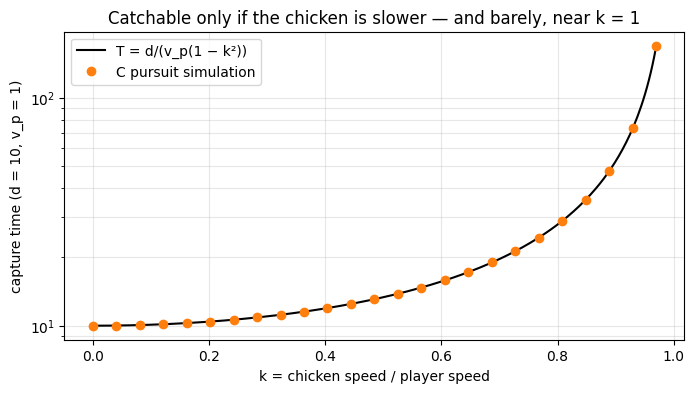

In [5]:
ks = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
Tsym = sp.lambdify(vc, T.subs({d: 10, vp: 1}))
print(f"{'k = vc/vp':>10s} {'C simulation':>14s} {'SymPy formula':>14s}")
for k in ks:
    tc = run_pursuit(exe, k)
    tf = capture_time(k)
    print(f"{k:10g} {('never' if tc is None else f'{tc:.4f}'):>14s} {('never' if tf is None else f'{float(Tsym(k)):.4f}'):>14s}")

kk = np.linspace(0, 0.97, 25)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.linspace(0, 0.97, 300), [capture_time(x) for x in np.linspace(0, 0.97, 300)], "k", label="T = d/(v_p(1 − k²))")
ax.plot(kk, [run_pursuit(exe, x) for x in kk], "o", color="C1", label="C pursuit simulation")
ax.set(xlabel="k = chicken speed / player speed", ylabel="capture time (d = 10, v_p = 1)", yscale="log",
       title="Catchable only if the chicken is slower — and barely, near k = 1")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

For $k \ll 1$ the chicken is basically standing still and $T \approx d/v_p$. As
$k \to 1^-$ the time diverges like $1/(1-k)$. For $k \ge 1$ the chaser never catches
up, which is why the chickens in §4 are given a flee speed slower than the player's.

# 4. The chase

Chickens wander with a jittered heading (random numbers from xorshift32: three
shifts and three XORs). Inside the panic radius (the ring around the player) they
flee at 0.75 times the player's speed. The player pursues the nearest chicken. Every
frame below was drawn by the C program into the 1-bit framebuffer and saved as raw
memory.

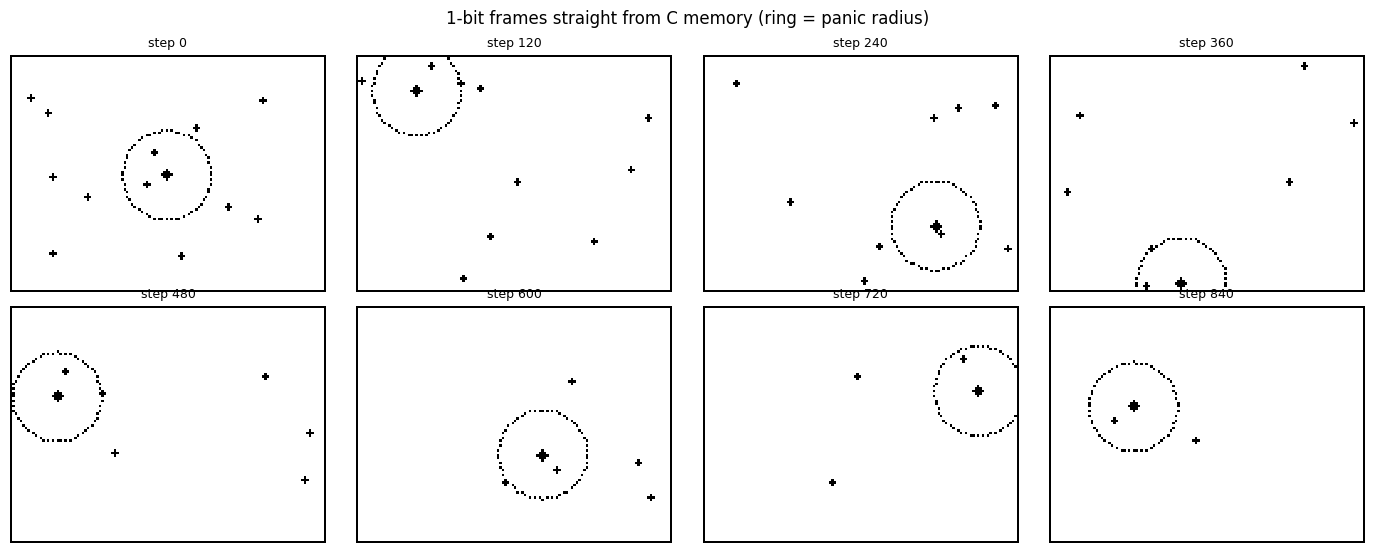

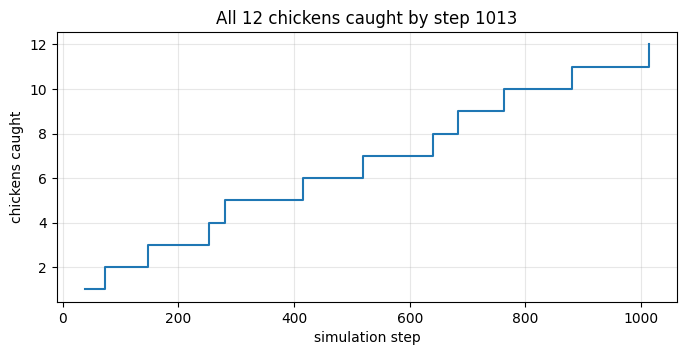

In [6]:
frames, catches = run_sim(exe, seed=7, steps=1500, every=60)
show = frames[:: max(1, len(frames)//8)][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.6))
for ax, f in zip(axes.flat, show):
    ax.imshow(read_pbm(f), cmap="gray_r", interpolation="nearest")
    ax.set_title(f"step {int(f.stem.split('_')[1]) * 60}", fontsize=9); ax.axis("off")
for ax in axes.flat[len(show):]:
    ax.axis("off")
plt.suptitle("1-bit frames straight from C memory (ring = panic radius)"); plt.tight_layout(); plt.show()

steps, counts = zip(*catches)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(steps, counts, where="post")
ax.set(xlabel="simulation step", ylabel="chickens caught", title=f"All {counts[-1]} chickens caught by step {steps[-1]}")
ax.grid(alpha=0.3); plt.show()

## Exercises
1. Make the chickens flee at 1.0× the player's speed. Using §3, predict what happens, then run it.
2. Change `W` to 120, which is not a power of two. Recompile and disassemble. What replaces `shl`?
3. Add a 2-bit (4-gray-level) framebuffer. What are the byte/shift formulas now?
4. Replace pure pursuit with *lead pursuit* (aim where the chicken will be). Does capture get faster?
5. Compile with `-O0` instead of `-O2` and compare the disassembly. What did the optimizer remove?